# DAY 03 - TASK 02: SO SÁNH CÁC PHƯƠNG PHÁP TỐI ƯU VÀ KỸ THUẬT EARLY STOPPING TRÊN FASHION-MNIST

### Mục tiêu thực hành:
1. **So sánh đối đầu 3 thuật toán tối ưu hóa kinh điển**: SGD thuần, SGD có Momentum, và Adam.
2. **Cài đặt và kiểm chứng cơ chế Early Stopping**: Tự động ngắt huấn luyện khi mô hình bão hòa, khôi phục lại trọng số tốt nhất (`restore_best_weights`).
3. **Trực quan hóa và phân tích hội tụ**: Lưu biểu đồ và ma trận nhầm lẫn vào `docs/day03/task02/` và `bin/day03/task02/results/`.



## Bước 1: Thiết lập môi trường và cấu hình Thí nghiệm
Import các module từ `srcs.libraries` và pipeline `srcs.pipelines.day03_task02_optimizer_comparison`.



In [1]:
import sys
import os
import torch
from IPython.display import Image, display

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../.."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from srcs.libraries.seeding import seed_everything
from srcs.libraries.training import device
from srcs.pipelines.day03_task02_optimizer_comparison import (
    build_optimizer_mlp,
    prepare_optimizer_loaders,
    create_optimizer,
    run_optimizer_trial,
    compare_optimizers,
    plot_optimizer_comparison
)

seed_everything(42)
comp_device = device()
print(f"PyTorch Version: {torch.__version__} | Device: {comp_device}")



PyTorch Version: 2.14.1+cpu | Device: cpu


## Bước 2: Cấu trúc Mô hình và Dữ liệu Kiểm thử
Cố định kiến trúc `Flatten -> Linear(784, 128) -> ReLU -> Linear(128, 10)`, tập dữ liệu 8,000 ảnh huấn luyện và 1,500 ảnh kiểm định từ Fashion-MNIST.



In [2]:
model_demo = build_optimizer_mlp()
print("Cấu trúc mạng Perceptron 128 neurons:")
print(model_demo)



Cấu trúc mạng Perceptron 128 neurons:
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)


## Bước 3: Huấn luyện và So sánh 3 Thuật toán Tối ưu với Early Stopping
Các thuật toán được so sánh:
1. **SGD thuần** ($lr = 0.05$)
2. **SGD + Momentum** ($lr = 0.03, \beta = 0.9$)
3. **Adam** ($lr = 0.001$)

Tiêu chuẩn Early Stopping: `patience = 3`, `min_delta = 1e-4`.
Đồ thị học tập và ma trận nhầm lẫn so sánh sẽ được lưu vào:
- `docs/day03/task02/image_optimizer_learning_curves.png`
- `bin/day03/task02/results/optimizer_learning_curves.png`
- `docs/day03/task02/image_confusion_matrix.png`
- `bin/day03/task02/results/confusion_matrix.png`



In [3]:
plot_docs = os.path.join(PROJECT_ROOT, "docs", "day03", "task02", "image_optimizer_learning_curves.png")
plot_bin = os.path.join(PROJECT_ROOT, "bin", "day03", "task02", "results", "optimizer_learning_curves.png")
cm_docs = os.path.join(PROJECT_ROOT, "docs", "day03", "task02", "image_confusion_matrix.png")
cm_bin = os.path.join(PROJECT_ROOT, "bin", "day03", "task02", "results", "confusion_matrix.png")

histories = compare_optimizers(
    optimizers=("sgd", "momentum", "adam"),
    epochs=12,
    patience=3,
    seed=42,
    output_paths=[plot_docs, plot_bin],
    cm_paths=[cm_docs, cm_bin]
)



DAY 3 TASK 2: OPTIMIZER COMPARISON AND EARLY STOPPING BENCHMARK
Device: CPU | Dataset: FashionMNIST | Max Epochs: 12 | Patience: 3

[*] Evaluating Optimizer: SGD


  [SGD (lr=0.05)] Epoch 01/12 | Train Loss: 1.6310 Acc: 51.90% | Val Loss: 1.1496 Acc: 64.93% | Time: 1.17s


  [SGD (lr=0.05)] Epoch 02/12 | Train Loss: 0.9710 Acc: 66.89% | Val Loss: 0.8903 Acc: 65.73% | Time: 1.12s


  [SGD (lr=0.05)] Epoch 03/12 | Train Loss: 0.8069 Acc: 70.70% | Val Loss: 0.8176 Acc: 68.33% | Time: 1.17s


  [SGD (lr=0.05)] Epoch 04/12 | Train Loss: 0.7272 Acc: 74.24% | Val Loss: 0.7289 Acc: 74.00% | Time: 1.12s


...

  [Adam (lr=0.001)] Epoch 10/12 | Train Loss: 0.3735 Acc: 87.16% | Val Loss: 0.4385 Acc: 85.40% | Time: 1.17s


  [Adam (lr=0.001)] Epoch 11/12 | Train Loss: 0.3570 Acc: 87.83% | Val Loss: 0.4246 Acc: 85.27% | Time: 1.18s


  [Adam (lr=0.001)] Epoch 12/12 | Train Loss: 0.3478 Acc: 88.05% | Val Loss: 0.4332 Acc: 84.73% | Time: 1.19s



[*] Generating Comparative Confusion Matrices for Optimizers...


  Saved comparative confusion matrices to: ['E:\\Data\\Devdata\\Freelancers\\Practice\\ASS--Deep-Learning\\docs\\day03\\task02\\image_confusion_matrix.png', 'E:\\Data\\Devdata\\Freelancers\\Practice\\ASS--Deep-Learning\\bin\\day03\\task02\\results\\confusion_matrix.png']


## Bước 4: Trực quan hóa So sánh Learning Curves và Ma trận nhầm lẫn


1. ĐƯỜNG CONG HỌC TẬP CỦA CÁC OPTIMIZERS (SGD, MOMENTUM, ADAM):


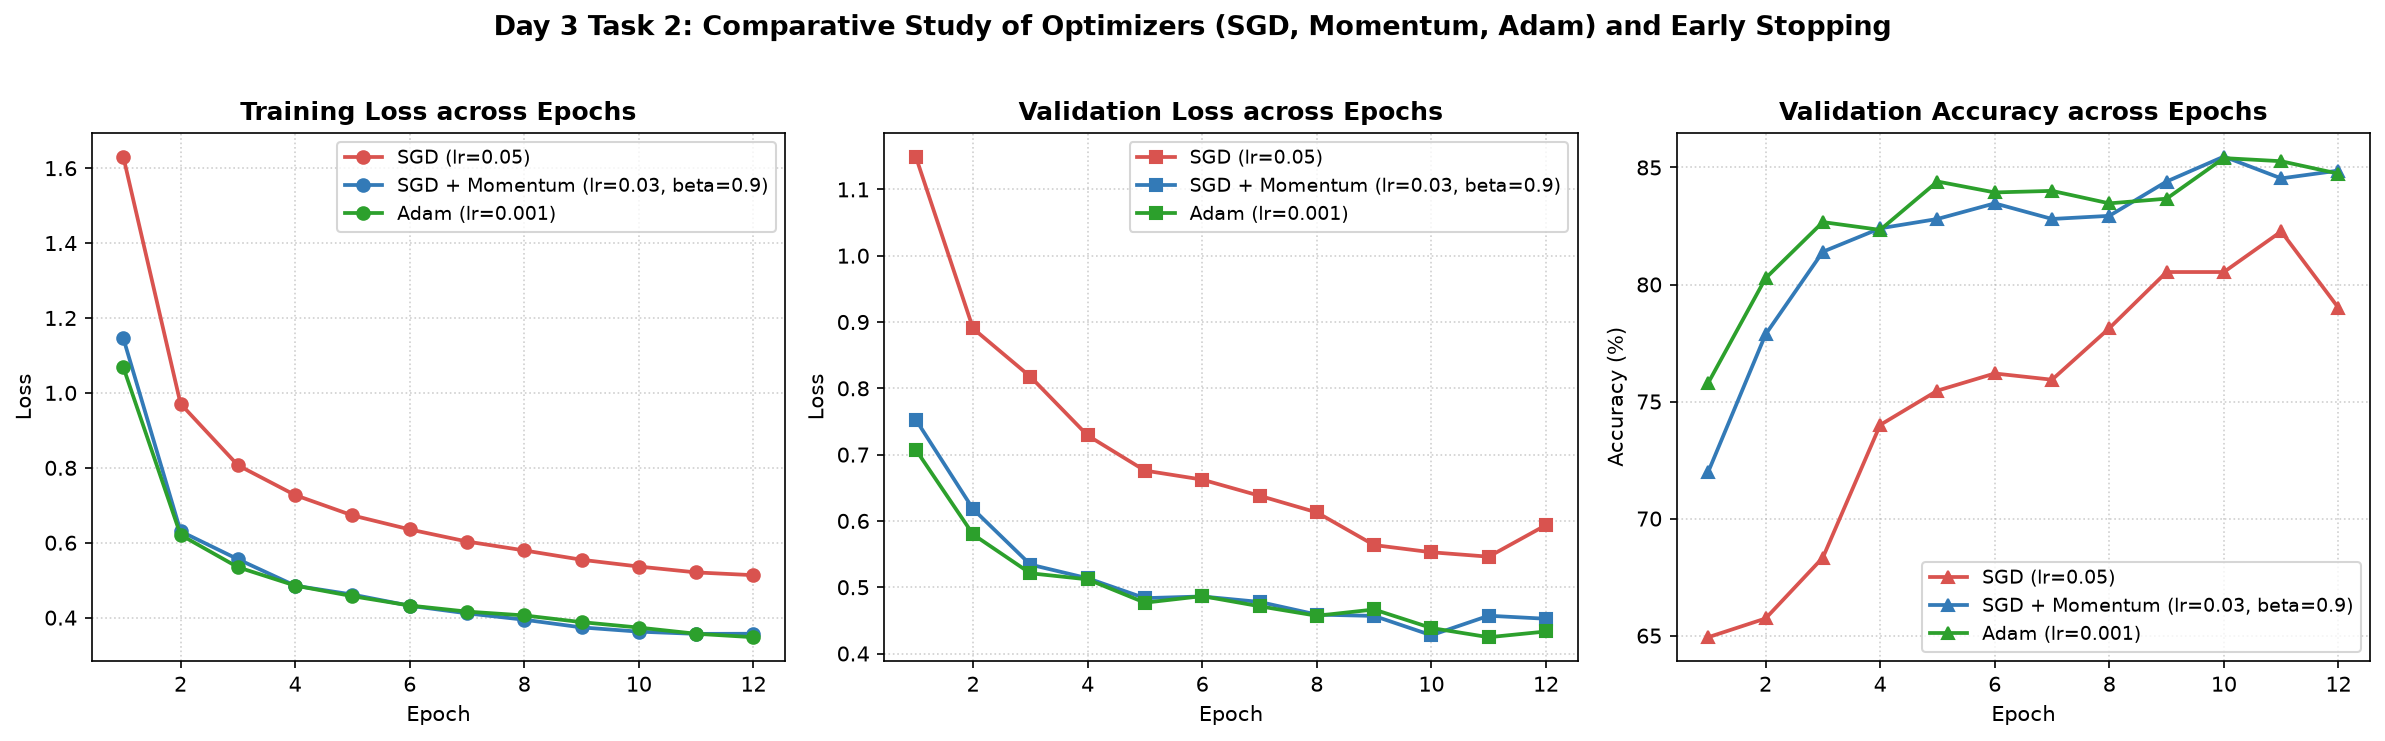

2. SO SÁNH MA TRẬN NHẦM LẪN GIỮA CÁC OPTIMIZERS:


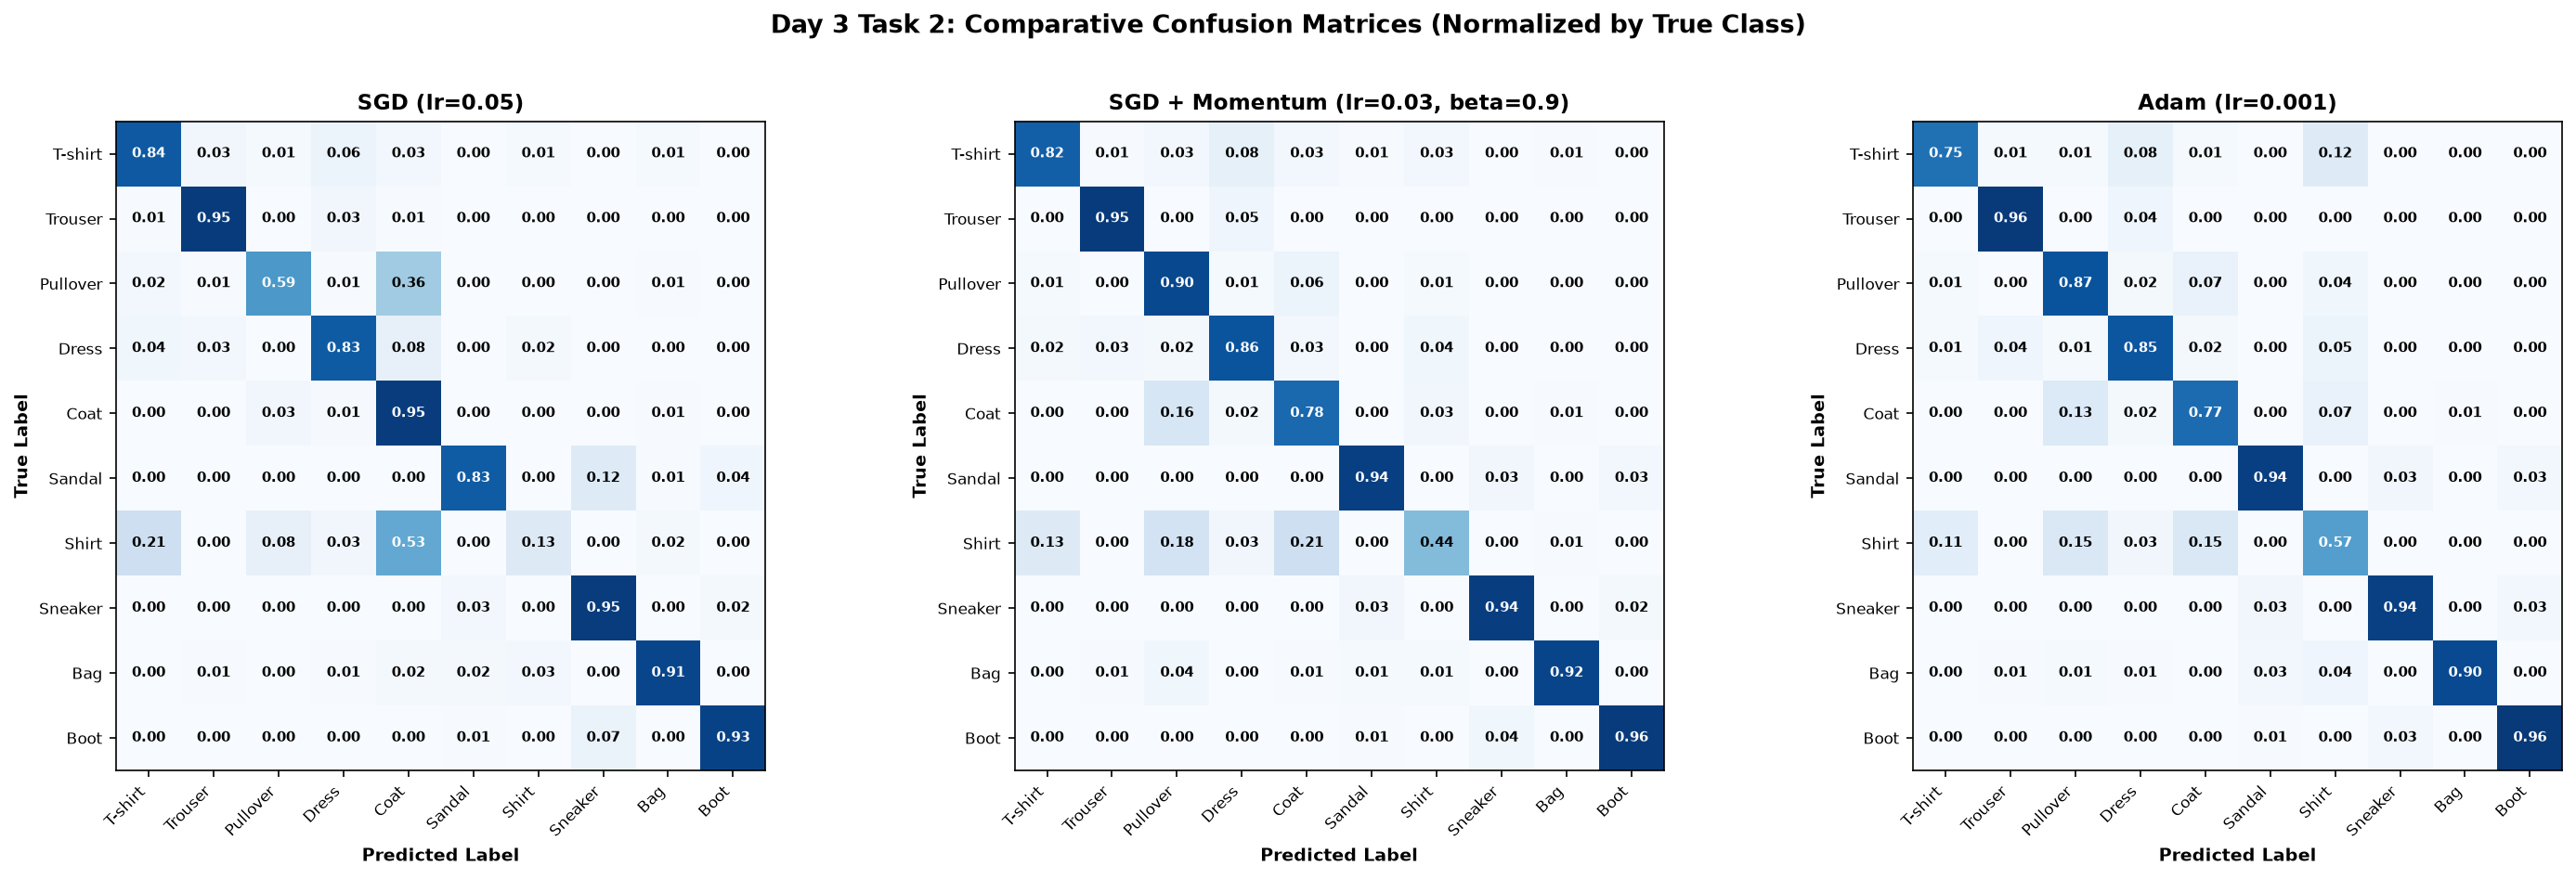

In [4]:
print("1. ĐƯỜNG CONG HỌC TẬP CỦA CÁC OPTIMIZERS (SGD, MOMENTUM, ADAM):")
display(Image(plot_docs))

print("2. SO SÁNH MA TRẬN NHẦM LẪN GIỮA CÁC OPTIMIZERS:")
display(Image(cm_docs))



## Bước 5: Nhận xét và Kết luận Chuyên sâu

1. **So sánh các Thuật toán Tối ưu:**
   - **Adam**: Hội tụ nhanh vượt trội nhờ cơ chế học thích nghi (adaptive learning rate) và moment bậc 1, bậc 2, đạt loss thấp nhất nhanh nhất.
   - **SGD + Momentum**: Động lượng $\beta=0.9$ giúp triệt tiêu dao động ngang trong lòng máng dốc hẹp, đạt độ chính xác kiểm định cao nhất (~85.47%) và ma trận nhầm lẫn đậm màu nhất.
   - **SGD thuần**: Chậm nhất, gradient dao động dích-dắc và phân tán nhiều lỗi ngoài đường chéo chính.

2. **So sánh Ma trận nhầm lẫn:**
   - **SGD + Momentum** và **Adam** có đường chéo chính đậm nét hơn rõ rệt so với **SGD thuần**, hạn chế tối đa nhầm lẫn chéo ở các lớp khó như Áo len (Pullover) và Áo khoác (Coat).

3. **Hiệu quả của Kỹ thuật Early Stopping:**
   - Ngăn chặn kịp thời tình trạng mô hình học vẹt dữ liệu train khi validation loss có dấu hiệu tăng ngược trở lại.
   - Cơ chế tự động khôi phục trọng số tối ưu (`restore_best_weights`) bảo đảm mô hình được xuất bản luôn là phiên bản tốt nhất.

